# Entrenamiento del modelo — Recomendador de proyectos y habilidades
El modelo apoya la plataforma de residencias profesionales con tres funciones:

| Función | Pregunta que responde | Técnica |
|---|---|---|
| **Emparejamiento** | ¿Qué proyectos se ajustan mejor a las habilidades de un alumno? | Similitud coseno sobre TF-IDF + LSA |
| **Habilidades sugeridas** | ¿Qué le conviene aprender al alumno? | Vecinos más cercanos (kNN) entre vacantes reales |
| **Perfil profesional** | ¿A qué perfil del mercado se parece el alumno? | Agrupamiento K-Means de las vacantes |

Las vacantes no tienen una etiqueta que predecir, así que el modelo es **no supervisado**. Para evaluarlo se usan pruebas con información oculta, explicadas en cada sección.

Datos de entrada: `data/processed/`, generados en `inspeccion_limpieza.ipynb`.

In [1]:
#importar las librerias
import json
import os
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator, PercentFormatter
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer, normalize

In [2]:
#Estilo de las graficas (el mismo del analisis exploratorio)
COLOR_PRINCIPAL = "#2a78d6"
COLOR_FONDO = "#fcfcfb"
COLOR_TEXTO = "#0b0b0b"
COLOR_TEXTO_SEC = "#52514e"
COLOR_MUTED = "#898781"

plt.rcParams.update({
    "figure.facecolor": COLOR_FONDO,
    "axes.facecolor": COLOR_FONDO,
    "savefig.facecolor": COLOR_FONDO,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": COLOR_TEXTO_SEC,
    "axes.titlecolor": COLOR_TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": COLOR_MUTED,
    "ytick.color": COLOR_MUTED,
    "xtick.labelcolor": COLOR_TEXTO_SEC,
    "ytick.labelcolor": COLOR_TEXTO_SEC,
    "text.color": COLOR_TEXTO,
    "font.size": 10,
    "legend.frameon": False,
    "figure.dpi": 110,
})
cmap_azul = LinearSegmentedColormap.from_list("azul", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])

def barras_horizontales(ax, serie, formato="{:.1%}"):
    serie = serie.sort_values()
    ax.barh(serie.index, serie.values, color=COLOR_PRINCIPAL, height=0.6)
    for i, valor in enumerate(serie.values):
        ax.text(valor + serie.max() * 0.01, i, formato.format(valor), va="center", fontsize=9, color=COLOR_TEXTO_SEC)
    ax.set_xlim(0, serie.max() * 1.18)
    ax.grid(axis="y", visible=False)

#Semilla para que los resultados sean reproducibles
SEMILLA = 42

## 1. Cargar datos y preparar las listas de habilidades
Se excluyen las **competencias blandas** y los **conceptos generales** (*Software Engineering*, *Computer Science*…): casi todas las vacantes los mencionan y no distinguen un perfil técnico de otro. En las pruebas previas, quitarlas mejoró el emparejamiento y los perfiles.
Se conservan las vacantes con al menos 4 habilidades técnicas.

In [3]:
carpeta_processed = "../../data/processed"
vacantes = pd.read_csv(f"{carpeta_processed}/vacantes_limpio.csv")
vacante_habilidad = pd.read_csv(f"{carpeta_processed}/vacantes_habilidades.csv")

CATEGORIAS_EXCLUIDAS = ["Competencias blandas", "Conceptos generales"]
MIN_HABILIDADES = 4

tecnicas = vacante_habilidad[~vacante_habilidad["categoria"].isin(CATEGORIAS_EXCLUIDAS)]
listas = tecnicas.groupby("id_vacante")["habilidad"].apply(list)
listas = listas[listas.str.len() >= MIN_HABILIDADES]

print(f"Vacantes utilizadas: {len(listas):,} de {len(vacantes):,}")
print(f"Habilidades técnicas distintas: {tecnicas['habilidad'].nunique():,}")

Vacantes utilizadas: 6,204 de 6,489
Habilidades técnicas distintas: 1,263


## 2. Representación de las vacantes
1. **Matriz binaria** (`MultiLabelBinarizer`): una columna por habilidad, 1 si la vacante la pide.
2. **TF-IDF**: da más peso a las habilidades específicas (*Spring Boot*) que a las muy comunes (*Git*), porque distinguen mejor un perfil.
3. **LSA** (`TruncatedSVD`): resume las ~1,200 habilidades en unas pocas dimensiones latentes, de modo que habilidades relacionadas (*React* y *TypeScript*) quedan cerca aunque no coincidan exactamente.

Se separa un 20 % de las vacantes como **prueba**: solo se usan para evaluar.

In [4]:
vocabulario = MultiLabelBinarizer(sparse_output=True).fit(listas)

listas_train, listas_test = train_test_split(listas, test_size=0.2, random_state=SEMILLA)
X_train = vocabulario.transform(listas_train).astype(float)

tfidf = TfidfTransformer().fit(X_train)
print(f"Entrenamiento: {len(listas_train):,} vacantes | Prueba: {len(listas_test):,} vacantes")
print(f"Tamaño del vocabulario: {len(vocabulario.classes_):,} habilidades")

Entrenamiento: 4,963 vacantes | Prueba: 1,241 vacantes
Tamaño del vocabulario: 1,263 habilidades


In [5]:
#Funciones de representacion: cada una convierte listas de habilidades en vectores normalizados
def representar_binario(X):
    return normalize(X)

def representar_tfidf(X):
    return normalize(tfidf.transform(X))

def crear_representacion_lsa(n_componentes):
    svd = TruncatedSVD(n_components=n_componentes, random_state=SEMILLA).fit(tfidf.transform(X_train))
    return lambda X: normalize(svd.transform(tfidf.transform(X)))

representaciones = {
    "Binaria": representar_binario,
    "TF-IDF": representar_tfidf,
    "LSA (50 dim.)": crear_representacion_lsa(50),
    "LSA (100 dim.)": crear_representacion_lsa(100),
    "LSA (200 dim.)": crear_representacion_lsa(200),
}

## 3. Evaluación del emparejamiento alumno → proyecto
No existe una etiqueta de "proyecto correcto" para un alumno, así que se usa una prueba indirecta:
1. A cada vacante de prueba se le asigna una **familia de puesto** a partir de su título (*Frontend*, *Backend*, *Embebidos*…). Solo se usan las vacantes cuyo título indica una única familia.
2. Se toma **la mitad de sus habilidades** como si fuera el perfil de un alumno.
3. Se buscan las 10 vacantes más parecidas y se mide qué porcentaje es de **la misma familia** (*precisión@10*).

Un buen modelo debe recomendar a un alumno con habilidades de frontend vacantes de frontend.

In [6]:
familias = {
    "Frontend": r"front ?-?end|\bui\b",
    "Backend": r"back ?-?end",
    "Full stack": r"full ?-?stack",
    "DevOps y cloud": r"devops|\bsre\b|site reliability|cloud|platform|infrastructure",
    "Datos e IA": r"\bdata\b|machine learning|\bml\b|\bai\b",
    "Embebidos": r"embedded|firmware",
    "Móvil": r"\bios\b|android|mobile",
    "QA y pruebas": r"\btest|\bqa\b|quality",
    "Seguridad": r"secur",
}
titulos = vacantes.set_index("id_vacante")["titulo"].str.lower()
coincidencias = pd.DataFrame({familia: titulos.str.contains(patron, regex=True) for familia, patron in familias.items()})
familia_vacante = coincidencias[coincidencias.sum(axis=1) == 1].idxmax(axis=1)

prueba_familia = listas_test[listas_test.index.isin(familia_vacante.index)]
etiquetas = np.array(familia_vacante.loc[prueba_familia.index].tolist())
print(f"Vacantes de prueba con una familia clara: {len(prueba_familia)}")
pd.Series(etiquetas).value_counts()

Vacantes de prueba con una familia clara: 354


Full stack        81
Embebidos         57
QA y pruebas      57
DevOps y cloud    39
Backend           39
Frontend          29
Datos e IA        22
Móvil             16
Seguridad         14
Name: count, dtype: int64

In [7]:
rng = np.random.default_rng(SEMILLA)
mitades = [list(rng.permutation(lista))[:max(2, len(lista) // 2)] for lista in prueba_familia]
X_consulta = vocabulario.transform(mitades).astype(float)
X_completas = vocabulario.transform(prueba_familia).astype(float)

def precision_familia(representar, k=10):
    similitud = representar(X_consulta) @ representar(X_completas).T
    similitud = similitud.toarray() if hasattr(similitud, "toarray") else np.asarray(similitud)
    np.fill_diagonal(similitud, -np.inf)   #no contar la propia vacante
    top = np.argsort(-similitud, axis=1)[:, :k]
    return (etiquetas[top] == etiquetas[:, None]).mean()

#Referencia: precision esperada si se recomendara al azar
azar = pd.Series(etiquetas).value_counts(normalize=True).pow(2).sum()

resultados_emparejamiento = pd.Series({nombre: precision_familia(rep) for nombre, rep in representaciones.items()})
resultados_emparejamiento.sort_values(ascending=False).round(3)

LSA (100 dim.)    0.393
LSA (200 dim.)    0.390
LSA (50 dim.)     0.387
TF-IDF            0.369
Binaria           0.366
dtype: float64

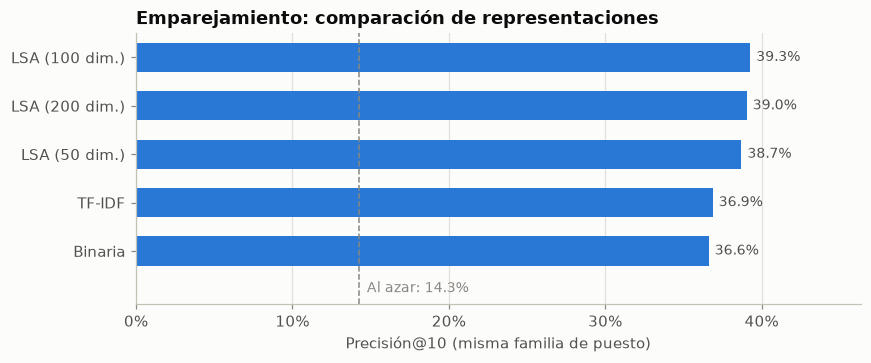

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
barras_horizontales(ax, resultados_emparejamiento)
ax.axvline(azar, color=COLOR_MUTED, linestyle="--", linewidth=1)
ax.set_ylim(-1.1, len(resultados_emparejamiento) - 0.5)
ax.text(azar + 0.005, -0.85, f"Al azar: {azar:.1%}", color=COLOR_MUTED, fontsize=9)
ax.xaxis.set_major_locator(MultipleLocator(0.1))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Precisión@10 (misma familia de puesto)")
ax.set_title("Emparejamiento: comparación de representaciones")
plt.show()

In [9]:
mejor_representacion = resultados_emparejamiento.idxmax()
N_COMPONENTES = int(mejor_representacion.split("(")[1].split()[0]) if "LSA" in mejor_representacion else None
print(f"Representación elegida: {mejor_representacion} "
      f"({resultados_emparejamiento.max():.1%} vs. {azar:.1%} al azar, {resultados_emparejamiento.max() / azar:.1f} veces mejor)")

Representación elegida: LSA (100 dim.) (39.3% vs. 14.3% al azar, 2.8 veces mejor)


## 4. Evaluación de las habilidades sugeridas
Prueba de **habilidades ocultas**: a cada vacante de prueba se le esconde el 30 % de sus habilidades y se pide al modelo que sugiera 10. Se mide:
- **Precisión@10**: qué parte de las 10 sugerencias eran habilidades ocultas.
- **Recall@10**: qué parte de las habilidades ocultas se recuperó.

Métodos comparados:
- **Popularidad** (referencia): sugiere siempre las habilidades más pedidas del mercado.
- **Coocurrencia**: sugiere las que más se piden junto con las que ya tiene.
- **kNN**: busca las vacantes más parecidas al alumno y sugiere las habilidades que esas vacantes piden.

In [10]:
FRACCION_OCULTA = 0.3

def ocultar(lista):
    lista = list(rng.permutation(lista))
    n_ocultas = max(1, round(len(lista) * FRACCION_OCULTA))
    return lista[n_ocultas:], lista[:n_ocultas]

rng = np.random.default_rng(SEMILLA)
pares = [ocultar(lista) for lista in listas_test]
X_observadas = vocabulario.transform([observadas for observadas, _ in pares]).astype(float)
indice = {habilidad: i for i, habilidad in enumerate(vocabulario.classes_)}
ocultas = [{indice[h] for h in ocultas} for _, ocultas in pares]

def evaluar_sugerencias(puntajes, k=10):
    puntajes = np.array(puntajes, dtype=float)
    puntajes[X_observadas.toarray() > 0] = -np.inf   #no sugerir lo que ya tiene
    top = np.argsort(-puntajes, axis=1)[:, :k]
    aciertos = np.array([len(set(fila) & reales) for fila, reales in zip(top, ocultas)])
    return {"precision@10": (aciertos / k).mean(),
            "recall@10": (aciertos / np.array([len(r) for r in ocultas])).mean()}

In [11]:
X_train_denso = X_train.toarray()
observadas_denso = X_observadas.toarray()

#Popularidad: numero de vacantes que piden cada habilidad
popularidad = X_train_denso.sum(axis=0)

#Coocurrencia: P(b | a) = vacantes con a y b / vacantes con a
coocurrencia = X_train_denso.T @ X_train_denso
condicional = coocurrencia / np.maximum(np.diag(coocurrencia)[:, None], 1)
np.fill_diagonal(condicional, 0)

def puntajes_knn(representar, k_vecinos):
    similitud = (representar(X_observadas) @ representar(X_train).T)
    similitud = similitud.toarray() if hasattr(similitud, "toarray") else np.asarray(similitud)
    umbral = -np.sort(-similitud, axis=1)[:, k_vecinos - 1:k_vecinos]
    similitud[similitud < umbral] = 0   #solo los k vecinos mas parecidos
    return similitud @ X_train_denso

metodos = {
    "Popularidad": np.tile(popularidad, (len(pares), 1)),
    "Coocurrencia": observadas_denso @ condicional,
}
for k_vecinos in [20, 50]:
    metodos[f"kNN TF-IDF (k={k_vecinos})"] = puntajes_knn(representar_tfidf, k_vecinos)
    metodos[f"kNN {mejor_representacion} (k={k_vecinos})"] = puntajes_knn(representaciones[mejor_representacion], k_vecinos)

resultados_sugerencias = pd.DataFrame({nombre: evaluar_sugerencias(p) for nombre, p in metodos.items()}).T
resultados_sugerencias.sort_values("recall@10", ascending=False).round(3)

,precision@10,recall@10
kNN TF-IDF (k=20),0.151,0.384
kNN TF-IDF (k=50),0.147,0.377
kNN LSA (100 dim.) (k=50),0.144,0.369
kNN LSA (100 dim.) (k=20),0.143,0.365
Coocurrencia,0.127,0.326
Popularidad,0.090,0.232


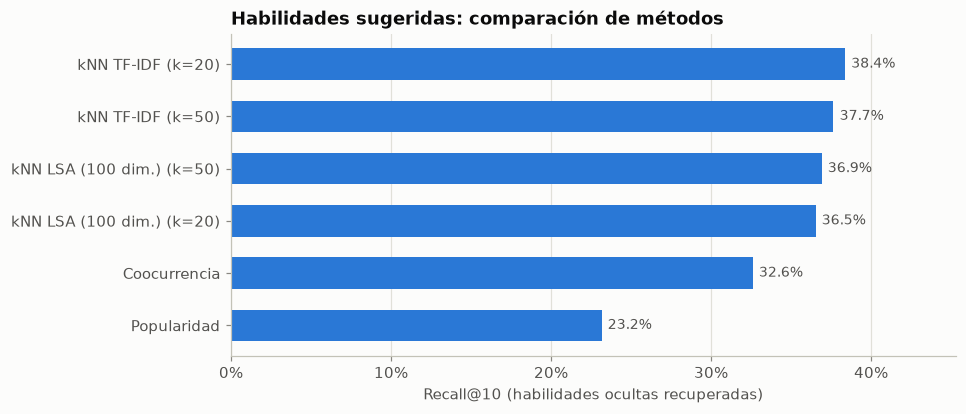

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
barras_horizontales(ax, resultados_sugerencias["recall@10"])
ax.xaxis.set_major_locator(MultipleLocator(0.1))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Recall@10 (habilidades ocultas recuperadas)")
ax.set_title("Habilidades sugeridas: comparación de métodos")
plt.show()

In [13]:
mejor_metodo = resultados_sugerencias["recall@10"].idxmax()
K_VECINOS = int(mejor_metodo.split("k=")[1].rstrip(")"))
REP_SUGERENCIAS = "TF-IDF" if "TF-IDF" in mejor_metodo else mejor_representacion
mejora = resultados_sugerencias.loc[mejor_metodo, "recall@10"] / resultados_sugerencias.loc["Popularidad", "recall@10"]
print(f"Método elegido: {mejor_metodo} — recupera {mejora:.1f} veces más habilidades ocultas que la popularidad")

Método elegido: kNN TF-IDF (k=20) — recupera 1.7 veces más habilidades ocultas que la popularidad


## 5. Perfiles profesionales (agrupamiento)
Se agrupan las vacantes con **K-Means** sobre la representación LSA. Cada grupo es un **perfil profesional** del mercado.

El coeficiente de silueta mide qué tan separados quedan los grupos (de −1 a 1). En datos de habilidades suele ser bajo porque los perfiles se solapan (un *full stack* comparte habilidades con *frontend* y *backend*), así que el número de grupos se elige también por **interpretabilidad**.

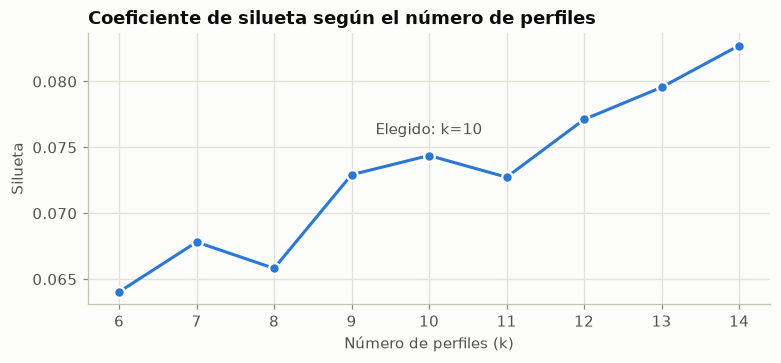

In [14]:
#Representacion LSA de todas las vacantes para el agrupamiento
svd_perfiles = TruncatedSVD(n_components=50, random_state=SEMILLA).fit(tfidf.transform(vocabulario.transform(listas)))
Z = normalize(svd_perfiles.transform(tfidf.transform(vocabulario.transform(listas))))

siluetas = {}
for k in range(6, 15):
    etiquetas_k = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(Z)
    siluetas[k] = silhouette_score(Z, etiquetas_k, sample_size=3000, random_state=SEMILLA)

K_PERFILES = 10

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(list(siluetas), list(siluetas.values()), color=COLOR_PRINCIPAL, linewidth=2, marker="o", markersize=7,
        markeredgecolor=COLOR_FONDO, markeredgewidth=1.5)
ax.annotate(f"Elegido: k={K_PERFILES}", xy=(K_PERFILES, siluetas[K_PERFILES]), xytext=(0, 14),
            textcoords="offset points", ha="center", color=COLOR_TEXTO_SEC)
ax.set_xlabel("Número de perfiles (k)")
ax.set_ylabel("Silueta")
ax.set_title("Coeficiente de silueta según el número de perfiles")
plt.show()

La silueta es baja en todo el rango (entre 0.06 y 0.08) y las diferencias a partir de 9 grupos son menores de 0.01, así que no hay un número de grupos claramente mejor.
Se eligen **10 perfiles**, un máximo local, porque producen grupos fáciles de interpretar y de explicar a los alumnos.
Los perfiles se nombran automáticamente comparando sus habilidades principales con una firma de habilidades típicas de cada perfil.

In [15]:
#Firmas de habilidades de cada perfil (para darles nombre)
firmas = {
    "Desarrollo embebido": ["Embedded Systems", "RTOS", "SPI", "I2C", "C/C++", "CAN"],
    "Frontend web": ["HTML", "CSS", "JavaScript", "Angular", "jQuery", "Bootstrap"],
    "Full stack JavaScript": ["React", "TypeScript", "Node.js", "PostgreSQL", "Next.js", "GraphQL"],
    "Backend Java": ["Java", "Spring Boot", "Spring", "Microservices", "Hibernate", "REST API"],
    "Desarrollo .NET": ["C#", ".NET", ".NET Core", "SQL Server", "ASP.NET", "Entity Framework"],
    "Cloud y DevOps": ["AWS", "Kubernetes", "Docker", "Go", "GCP", "Terraform"],
    "Datos e IA": ["Machine Learning", "Artificial Intelligence", "Data Science", "Data Analysis", "Python", "Spark"],
    "Calidad y pruebas": ["Software Testing", "Test Automation", "Debugging", "Code Review", "Selenium", "Quality Assurance"],
    "Sistemas y C/C++": ["C++", "C", "Linux", "Python", "Operating Systems", "Bash"],
}

kmeans = KMeans(n_clusters=K_PERFILES, n_init=10, random_state=SEMILLA).fit(Z)
T_todas = normalize(tfidf.transform(vocabulario.transform(listas))).toarray()

perfiles = []
for grupo in range(K_PERFILES):
    mascara = kmeans.labels_ == grupo
    clave = vocabulario.classes_[np.argsort(-T_todas[mascara].mean(axis=0))[:10]].tolist()
    afinidad = {nombre: len(set(clave) & set(firma)) for nombre, firma in firmas.items()}
    nombre, puntos = max(afinidad.items(), key=lambda par: par[1])
    familia = familia_vacante.reindex(listas.index[mascara]).value_counts(normalize=True)
    perfiles.append({
        "grupo": grupo,
        "perfil": nombre if puntos >= 2 else "Otros",
        "vacantes": int(mascara.sum()),
        "habilidades_clave": clave,
        "familia_titulo_principal": f"{familia.index[0]} ({familia.iloc[0]:.0%})" if len(familia) else "—",
    })

tabla_perfiles = pd.DataFrame(perfiles).sort_values("vacantes", ascending=False)
tabla_perfiles.assign(habilidades_clave=tabla_perfiles["habilidades_clave"].str[:6].str.join(", "))

,grupo,perfil,vacantes,habilidades_clave,familia_titulo_principal
9,9,Backend Java,1056,"Java, Agile, SQL, Git, Spring Boot, REST API",QA y pruebas (32%)
5,5,Cloud y DevOps,904,"AWS, Kubernetes, Go, Docker, Python, GCP",Backend (32%)
4,4,Desarrollo .NET,756,"C#, .NET, SQL Server, SQL, .NET Core, Angular",Full stack (36%)
0,0,Sistemas y C/C++,749,"C++, C, Python, Linux, Java, C#",Embebidos (58%)
6,6,Full stack JavaScript,718,"React, TypeScript, Node.js, AWS, JavaScript, P...",Full stack (48%)
2,2,Frontend web,691,"HTML, CSS, JavaScript, React, Angular, Git",Frontend (38%)
7,7,Calidad y pruebas,477,"Software Testing, Software Design, Project Man...",QA y pruebas (52%)
1,1,Desarrollo embebido,408,"C/C++, Embedded Systems, SPI, I2C, RTOS, Linux",Embebidos (87%)
3,3,Datos e IA,338,"Machine Learning, Artificial Intelligence, Pyt...",Datos e IA (51%)
8,8,Otros,107,"Software user interfaces, Operating Systems, N...",Datos e IA (62%)


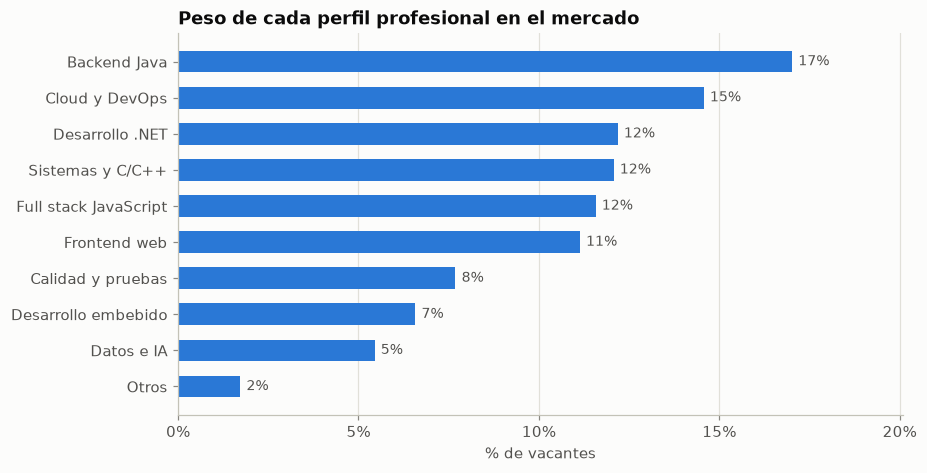

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
tamanos = tabla_perfiles.groupby("perfil")["vacantes"].sum() / len(listas)
barras_horizontales(ax, tamanos, formato="{:.0%}")
ax.xaxis.set_major_locator(MultipleLocator(0.05))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("% de vacantes")
ax.set_title("Peso de cada perfil profesional en el mercado")
plt.show()

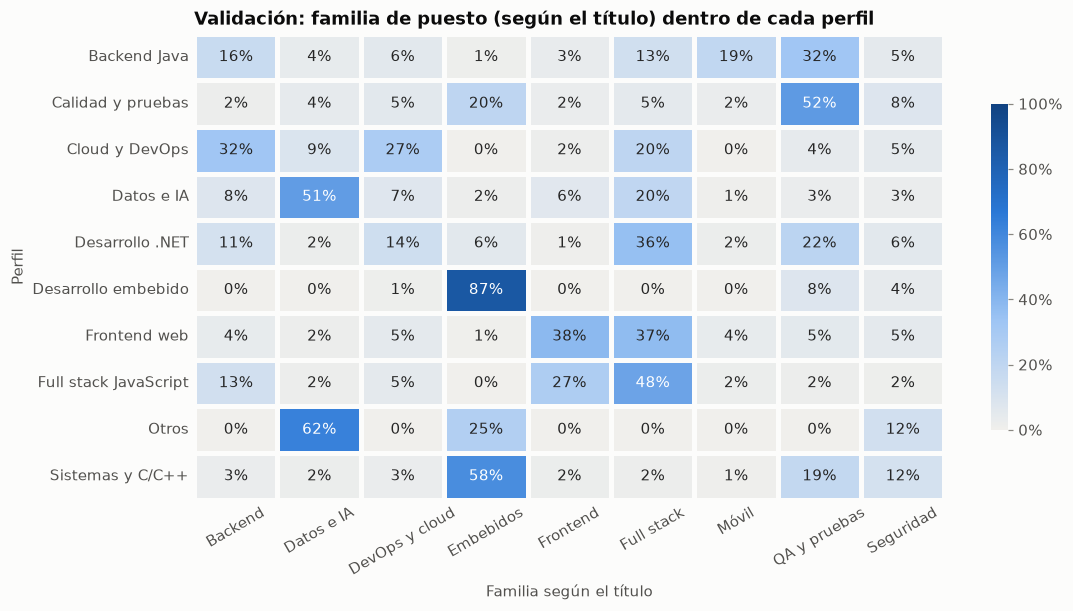

In [17]:
#Validacion: familia de puesto (segun el titulo) dentro de cada perfil
validacion = pd.crosstab(
    pd.Series(kmeans.labels_, index=listas.index).map(tabla_perfiles.set_index("grupo")["perfil"]).rename("Perfil"),
    familia_vacante.reindex(listas.index).rename("Familia según el título"),
    normalize="index",
)

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(validacion, cmap=cmap_azul, vmin=0, vmax=1, annot=True, fmt=".0%", linewidths=2, linecolor=COLOR_FONDO,
            cbar_kws={"format": PercentFormatter(1, decimals=0), "shrink": 0.7}, ax=ax)
ax.grid(False)
ax.tick_params(length=0)
ax.tick_params(axis="x", labelrotation=30)
ax.set_title("Validación: familia de puesto (según el título) dentro de cada perfil")
plt.show()

Menos de un tercio de las vacantes tiene una familia clara en el título, así que la tabla es una validación parcial. Aun así, los perfiles con firma clara (*Desarrollo embebido*, *Frontend web*, *Calidad y pruebas*) concentran su familia esperada.

## 6. Entrenamiento del modelo final
Con los métodos y parámetros elegidos, se reentrena todo con **todas** las vacantes.

In [18]:
X_todas = vocabulario.transform(listas).astype(float)
tfidf_final = TfidfTransformer().fit(X_todas)
svd_final = TruncatedSVD(n_components=N_COMPONENTES or 100, random_state=SEMILLA).fit(tfidf_final.transform(X_todas))

def representar_final(X):
    #Representacion elegida para el emparejamiento
    if N_COMPONENTES:
        return normalize(svd_final.transform(tfidf_final.transform(X)))
    return normalize(tfidf_final.transform(X))

def representar_sugerencias(X):
    return normalize(tfidf_final.transform(X)) if REP_SUGERENCIAS == "TF-IDF" else representar_final(X)

#Matrices de las vacantes de referencia (para sugerir habilidades)
vacantes_referencia = representar_sugerencias(X_todas)
vacantes_binaria = X_todas.tocsr()

categoria_habilidad = tecnicas.drop_duplicates("habilidad").set_index("habilidad")["categoria"].to_dict()

## 7. Prueba con un alumno de ejemplo
Se simula lo que hará el microservicio: un alumno con sus habilidades y varios proyectos publicados en la plataforma.

In [19]:
def vectorizar(habilidades):
    conocidas = [h for h in habilidades if h in indice]
    return vocabulario.transform([conocidas]).astype(float), conocidas

def perfil_alumno(habilidades):
    X, _ = vectorizar(habilidades)
    z = normalize(svd_perfiles.transform(tfidf.transform(X)))
    grupo = int(kmeans.predict(z)[0])
    info = tabla_perfiles.set_index("grupo").loc[grupo]
    faltantes = [h for h in info["habilidades_clave"] if h not in habilidades][:5]
    return {"perfil": info["perfil"], "habilidades_clave_faltantes": faltantes}

def sugerir_habilidades(habilidades, n=8):
    X, conocidas = vectorizar(habilidades)
    similitud = (representar_sugerencias(X) @ vacantes_referencia.T)
    similitud = np.asarray(similitud.toarray() if hasattr(similitud, "toarray") else similitud).ravel()
    vecinos = np.argsort(-similitud)[:K_VECINOS]
    puntajes = similitud[vecinos] @ vacantes_binaria[vecinos].toarray()
    puntajes[[indice[h] for h in conocidas]] = -np.inf
    top = np.argsort(-puntajes)[:n]
    return [(vocabulario.classes_[i], categoria_habilidad.get(vocabulario.classes_[i], "")) for i in top]

def recomendar_proyectos(habilidades, proyectos):
    X_alumno, _ = vectorizar(habilidades)
    X_proyectos = vocabulario.transform([[h for h in p["habilidades"] if h in indice] for p in proyectos]).astype(float)
    similitud = np.asarray(representar_final(X_alumno) @ representar_final(X_proyectos).T).ravel()
    filas = []
    for proyecto, afinidad in zip(proyectos, similitud):
        filas.append({
            "proyecto": proyecto["titulo"],
            "afinidad": round(max(float(afinidad), 0.0), 3),
            "coincidencias": ", ".join(h for h in proyecto["habilidades"] if h in habilidades),
            "le_faltan": ", ".join(h for h in proyecto["habilidades"] if h not in habilidades),
        })
    return pd.DataFrame(filas).sort_values("afinidad", ascending=False).reset_index(drop=True)

In [20]:
alumno = ["Java", "Spring Boot", "SQL", "Git", "HTML"]

proyectos_ejemplo = [
    {"titulo": "Sistema de inventarios web", "habilidades": ["Java", "Spring Boot", "PostgreSQL", "REST API", "Docker"]},
    {"titulo": "Portal web institucional", "habilidades": ["HTML", "CSS", "JavaScript", "React"]},
    {"titulo": "Tablero de análisis de ventas", "habilidades": ["Python", "SQL", "Machine Learning", "Data Analysis"]},
    {"titulo": "Firmware para sensor IoT", "habilidades": ["C", "Embedded Systems", "RTOS", "I2C"]},
    {"titulo": "Migración de servidores a la nube", "habilidades": ["AWS", "Docker", "Kubernetes", "Terraform", "Linux"]},
]

print("Perfil:", perfil_alumno(alumno))
print("Habilidades sugeridas:", sugerir_habilidades(alumno))
recomendar_proyectos(alumno, proyectos_ejemplo)

Perfil: {'perfil': 'Backend Java', 'habilidades_clave_faltantes': ['Agile', 'REST API', 'Spring', 'Jira', 'Jenkins']}
Habilidades sugeridas: [('JavaScript', 'Lenguajes'), ('Agile', 'Metodologías y gestión'), ('AWS', 'Cloud'), ('CSS', 'Lenguajes'), ('REST API', 'Arquitectura y buenas prácticas'), ('React', 'Frameworks y librerías'), ('Angular', 'Frameworks y librerías'), ('Microservices', 'Arquitectura y buenas prácticas')]


,proyecto,afinidad,coincidencias,le_faltan
0,Sistema de inventarios web,0.492,"Java, Spring Boot","PostgreSQL, REST API, Docker"
1,Portal web institucional,0.273,HTML,"CSS, JavaScript, React"
2,Tablero de análisis de ventas,0.180,SQL,"Python, Machine Learning, Data Analysis"
3,Migración de servidores a la nube,0.014,,"AWS, Docker, Kubernetes, Terraform, Linux"
4,Firmware para sensor IoT,0.000,,"C, Embedded Systems, RTOS, I2C"


## 8. Guardar el modelo
Se guarda en formato `.pkl` un diccionario con los componentes entrenados (solo objetos de scikit-learn y arreglos), más dos archivos JSON:
- `metadatos_recomendador.json`: parámetros, métricas y perfiles.
- `normalizacion_habilidades.json`: diccionario para normalizar las habilidades que lleguen desde la plataforma.

In [21]:
import shutil

modelo = {
    "vocabulario": vocabulario,
    "tfidf": tfidf_final,
    "svd": svd_final if N_COMPONENTES else None,
    "rep_sugerencias": REP_SUGERENCIAS,
    "k_vecinos": K_VECINOS,
    "vacantes_referencia": vacantes_referencia,
    "vacantes_binaria": vacantes_binaria,
    "tfidf_perfiles": tfidf,
    "svd_perfiles": svd_perfiles,
    "kmeans": kmeans,
    "perfiles": tabla_perfiles.set_index("grupo")[["perfil", "habilidades_clave"]].to_dict(orient="index"),
    "categorias": categoria_habilidad,
}

carpeta_artefactos = "../artefactos"
os.makedirs(carpeta_artefactos, exist_ok=True)
ruta_modelo = os.path.join(carpeta_artefactos, "modelo_recomendador.pkl")
with open(ruta_modelo, "wb") as f:
    pickle.dump(modelo, f)

metadatos = {
    "modelo": "Recomendador de proyectos y habilidades",
    "datos_entrenamiento": {"fuente": "LinkedIn Software Engineering Jobs (Kaggle)", "vacantes": len(listas),
                            "habilidades": len(vocabulario.classes_)},
    "emparejamiento": {"representacion": mejor_representacion,
                       "precision_familia@10": round(float(resultados_emparejamiento.max()), 4),
                       "precision_azar": round(float(azar), 4)},
    "sugerencias": {"metodo": mejor_metodo, "k_vecinos": K_VECINOS,
                    "precision@10": round(float(resultados_sugerencias.loc[mejor_metodo, "precision@10"]), 4),
                    "recall@10": round(float(resultados_sugerencias.loc[mejor_metodo, "recall@10"]), 4)},
    "perfiles": {"k": K_PERFILES, "silueta": round(float(siluetas[K_PERFILES]), 4),
                 "nombres": tabla_perfiles["perfil"].tolist()},
    "categorias_excluidas": CATEGORIAS_EXCLUIDAS,
    "version_sklearn": sklearn.__version__,
}
with open(os.path.join(carpeta_artefactos, "metadatos_recomendador.json"), "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

shutil.copy(f"{carpeta_processed}/normalizacion_habilidades.json", carpeta_artefactos)

print(f"Modelo guardado en {ruta_modelo} ({os.path.getsize(ruta_modelo) / 1e6:.1f} MB)")

Modelo guardado en ../artefactos\modelo_recomendador.pkl (3.6 MB)


In [22]:
#Comprobar que el modelo guardado se carga con pickle y da el mismo resultado
with open(ruta_modelo, "rb") as f:
    modelo_cargado = pickle.load(f)

X_prueba = modelo_cargado["vocabulario"].transform([alumno]).astype(float)
z = normalize(modelo_cargado["svd_perfiles"].transform(modelo_cargado["tfidf_perfiles"].transform(X_prueba)))
grupo = int(modelo_cargado["kmeans"].predict(z)[0])
print("Perfil con el modelo cargado:", modelo_cargado["perfiles"][grupo]["perfil"])

Perfil con el modelo cargado: Backend Java


## 9. Conclusiones
**Emparejamiento alumno → proyecto**
- La representación **LSA de 100 dimensiones** es la mejor: el 39.3 % de las 10 vacantes recomendadas son de la misma familia de puesto, **2.8 veces más que al azar** (14.3 %). Supera a TF-IDF (36.9 %) y a la representación binaria (36.6 %) porque reconoce habilidades relacionadas aunque no coincidan exactamente.
- La métrica es conservadora: muchas vacantes de otra familia también son adecuadas (un *full stack* para un alumno de *frontend*).

**Habilidades sugeridas**
- **kNN con TF-IDF (20 vecinos)** recupera el 38.4 % de las habilidades ocultas en sus 10 sugerencias, **1.7 veces más que sugerir las más populares** (23.2 %) y mejor que la coocurrencia (32.6 %).

**Perfiles profesionales**
- 10 perfiles: Backend Java (17 %), Cloud y DevOps (15 %), .NET (12 %), Sistemas y C/C++ (12 %), Full stack JavaScript (12 %), Frontend web (11 %), Calidad y pruebas (8 %), Desarrollo embebido (7 %), Datos e IA (5 %) y un grupo pequeño de *Otros* (2 %).
- Los perfiles más específicos coinciden con el título de la vacante: Desarrollo embebido (87 %), Calidad y pruebas (52 %), Datos e IA (51 %).

**Ejemplo:** un alumno con Java, Spring Boot, SQL, Git y HTML queda en el perfil *Backend Java*; el proyecto más afín es el sistema de inventarios con Spring Boot y se le sugiere aprender JavaScript, Agile, AWS y REST API.

**Limitaciones**
- Entrenado con vacantes internacionales de software (2023). Cuando la plataforma acumule proyectos y postulaciones reales, conviene reentrenarlo con esos datos.
- Las habilidades que el modelo no conoce (fuera de las 1,263 del vocabulario) se ignoran; el backend debe normalizarlas antes con `normalizacion_habilidades.json` e informar cuáles no reconoció.
- Las competencias blandas no forman parte del modelo técnico.

**Archivos generados** en `analisis/modelo/artefactos/`: `modelo_recomendador.pkl`, `metadatos_recomendador.json` y `normalizacion_habilidades.json`.